# Retail Orders — Cleaning & Loading

Clean the raw orders file, add price and profit columns, and load it into SQL Server for analysis.

In [2]:
# Download (run once, needs a Kaggle API token)
# !kaggle datasets download ankitbansal06/retail-orders -f orders.csv

In [3]:
import zipfile

with zipfile.ZipFile('orders.csv.zip') as z:
    z.extractall()

## Load and inspect

In [4]:
import pandas as pd

df = pd.read_csv('orders.csv', na_values=['Not Available', 'unknown'])
print(df.shape)
df.isna().sum()

(9994, 16)


Order Id            0
Order Date          0
Ship Mode           6
Segment             0
Country             0
City                0
State               0
Postal Code         0
Region              0
Category            0
Sub Category        0
Product Id          0
cost price          0
List Price          0
Quantity            0
Discount Percent    0
dtype: int64

In [5]:
df.head()

,Order Id,Order Date,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub Category,Product Id,cost price,List Price,Quantity,Discount Percent
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5


## Clean column names and types

In [6]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df['order_date'] = pd.to_datetime(df['order_date'], format='%Y-%m-%d')
df.dtypes

order_id                     int64
order_date          datetime64[ns]
ship_mode                   object
segment                     object
country                     object
city                        object
state                       object
postal_code                  int64
region                      object
category                    object
sub_category                object
product_id                  object
cost_price                   int64
list_price                   int64
quantity                     int64
discount_percent             int64
dtype: object

## Remove rows with no price
507 rows (~5%) have both cost and list price at 0. They carry no money information, so I dropped them.

In [7]:
no_price = (df['list_price'] == 0) & (df['cost_price'] == 0)
print('Rows with no price:', no_price.sum())

df = df[~no_price].copy()
print('Rows left:', len(df))

Rows with no price: 507
Rows left: 9487


## Add price and profit columns
Per unit: discount, sale price, profit. Per order line: revenue and total profit (× quantity).

In [8]:
df['discount'] = df['list_price'] * df['discount_percent'] * 0.01
df['sale_price'] = df['list_price'] - df['discount']
df['profit'] = df['sale_price'] - df['cost_price']

df['revenue'] = df['sale_price'] * df['quantity']
df['total_profit'] = df['profit'] * df['quantity']

df[['list_price', 'discount_percent', 'sale_price', 'cost_price', 'profit', 'quantity', 'revenue']].head()

,list_price,discount_percent,sale_price,cost_price,profit,quantity,revenue
0,260,2,254.8,240,14.8,2,509.6
1,730,3,708.1,600,108.1,3,2124.3
2,10,5,9.5,10,-0.5,2,19.0
3,960,2,940.8,780,160.8,5,4704.0
4,20,5,19.0,20,-1.0,2,38.0


## Sanity checks

In [9]:
print('Duplicate order ids:', df['order_id'].duplicated().sum())
print('Date range:', df['order_date'].min().date(), 'to', df['order_date'].max().date())
print('Lines sold below cost:', (df['profit'] < 0).sum())
print('Total revenue:', round(df['revenue'].sum()))
print('Total profit:', round(df['total_profit'].sum()))
df['ship_mode'].value_counts(dropna=False)

Duplicate order ids: 0
Date range: 2022-01-01 to 2023-12-31
Lines sold below cost: 3997
Total revenue: 11079328
Total profit: 1039928


ship_mode
Standard Class    5637
Second Class      1869
First Class       1450
Same Day           525
NaN                  6
Name: count, dtype: int64

42% of lines sell below cost — but list price equals cost on 3,955 lines, so any discount makes them negative. Checked further in SQL.

## Load into SQL Server
Run `CREATE DATABASE retail_db;` in SSMS first.

In [10]:
import sqlalchemy as sal

engine = sal.create_engine(
    'mssql+pyodbc://@DESKTOP-G66G5TF/retail_db'
    '?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes'
)

df.to_sql('df_orders', con=engine, index=False, if_exists='replace')
print('Loaded', len(df), 'rows')

Loaded 9487 rows


## Charts
Four charts, one point each. Numbers checked against the SQL results first.

In [11]:
import matplotlib.pyplot as plt
import os

os.makedirs('charts', exist_ok=True)

### 1. Do bigger discounts hurt margin?

In [12]:
disc = df.groupby('discount_percent')[['revenue', 'total_profit']].sum()
disc['margin_pct'] = disc['total_profit'] / disc['revenue'] * 100
disc

,revenue,total_profit,margin_pct
discount_percent,,,
2,2667266.0,285796.0,10.714942
3,2825794.3,276904.3,9.799167
4,2736182.4,252732.4,9.236680
5,2850085.5,224495.5,7.876799


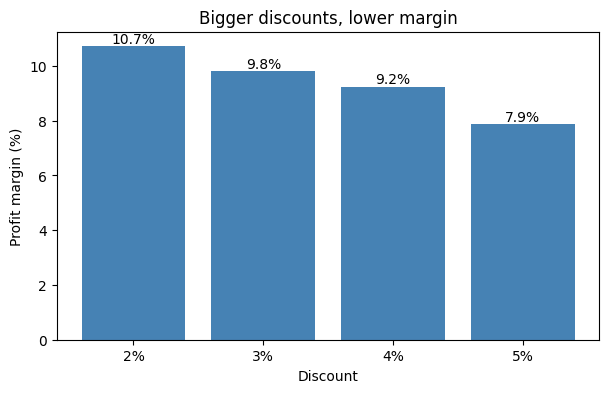

In [13]:
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(disc.index.astype(str) + '%', disc['margin_pct'], color ='steelblue')
ax.bar_label(bars, fmt='%.1f%%')
ax.set_title('Bigger discounts, lower margin')
ax.set_xlabel('Discount')
ax.set_ylabel('Profit margin (%)')
plt.savefig('charts/discount_vs_margin.png', dpi=150, bbox_inches='tight')
plt.show()

Margin drops at every discount step: 10.7% at 2% down to 7.9% at 5%. Order counts are about the same at each level, so bigger discounts don't seem to bring more sales.

### 2. Which sub-categories have the thinnest margins?

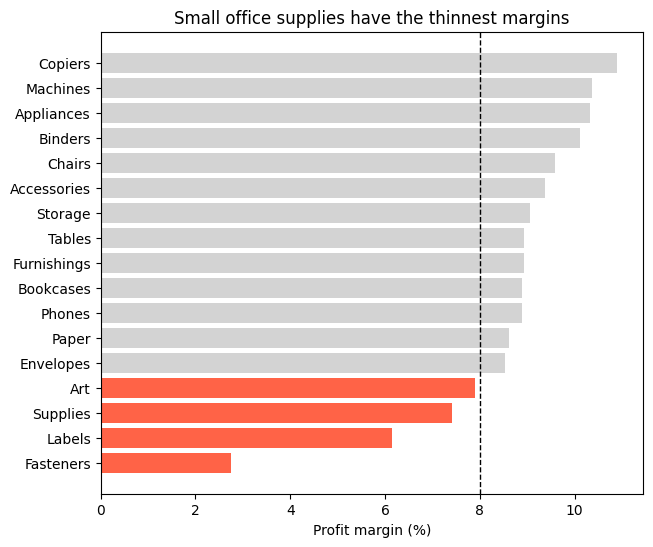

In [14]:
sub = df.groupby('sub_category')[['revenue', 'total_profit']].sum()
sub['margin_pct'] = sub['total_profit'] / sub['revenue'] * 100
sub = sub.sort_values('margin_pct')

# red if under 8%, grey otherwise
colors = ['tomato' if m < 8 else 'lightgray' for m in sub['margin_pct']]

fig,ax = plt.subplots(figsize=(7,6))
ax.barh(sub.index, sub['margin_pct'], color=colors)
ax.axvline(8, color='black', linestyle='--', linewidth=1)   # 8% cut-off from SQL Q5
ax.set_title('Small office supplies have the thinnest margins')
ax.set_xlabel('Profit margin (%)')
plt.savefig('charts/margin_by_subcategory.png', dpi=150, bbox_inches='tight')
plt.show()

Fasteners, labels, supplies and art are all under 8%. Cheap items where list price often equals cost.

### 3. How did monthly revenue change from 2022 to 2023?

In [15]:
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
# months down the side, years across the top (same as SQL Q9)
monthly = df.pivot_table(index='month', columns='year', values='revenue', aggfunc='sum')
monthly

year,2022,2023
month,,
1,437431.3,434765.5
2,444011.1,731638.8
3,394105.2,393051.9
4,476400.9,543231.5
5,413625.5,410707.9
6,465300.3,328939.0
7,375278.4,422533.7
8,534562.4,465010.3
9,433887.0,420620.5


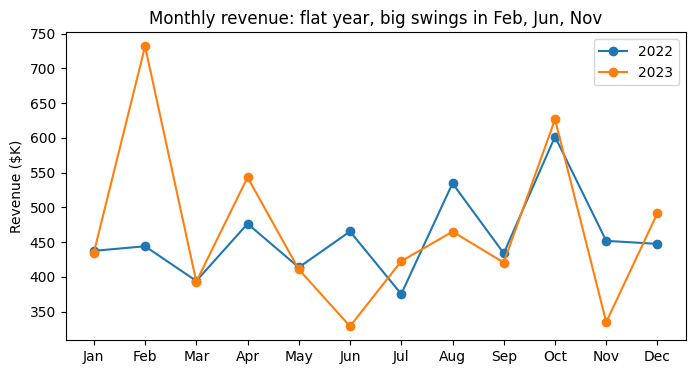

In [16]:
fig,ax = plt.subplots(figsize=(8,4))
ax.plot(monthly.index, monthly[2022] / 1000, marker='o', label='2022')
ax.plot(monthly.index, monthly[2023] / 1000, marker='o', label='2023')
ax.set_xticks(range(1,13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Monthly revenue: flat year, big swings in Feb, Jun, Nov')
ax.set_ylabel('Revenue ($K)')
ax.legend()
plt.savefig('charts/monthly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

2023 ended about where 2022 did (+2.3%), but Feb jumped ~65% and Jun/Nov dropped 25-30%. Worth asking the business what happened those months.

### 4. Why do so many lines sell below cost?

In [17]:
df['price_setup'] = (df['list_price'] == df['cost_price']).map({True: 'List price = cost', False: 'List price > cost'})
df['is_loss'] = df['profit'] < 0
# mean of True/False = share of losing lines
loss = df.groupby('price_setup')['is_loss'].mean() * 100
loss

price_setup
List price = cost    100.000000
List price > cost      0.759219
Name: is_loss, dtype: float64

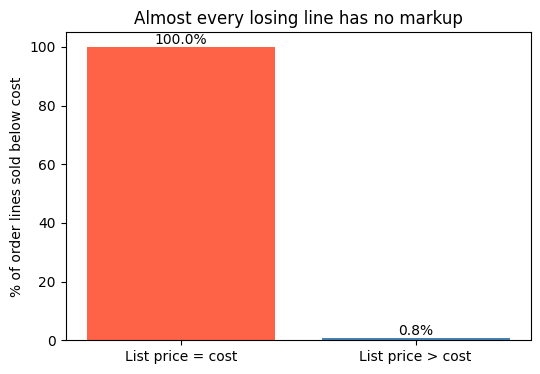

In [18]:
fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(loss.index, loss, color=['tomato', 'steelblue'])
ax.bar_label(bars, fmt='%.1f%%')
ax.set_title('Almost every losing line has no markup')
ax.set_ylabel('% of order lines sold below cost')
plt.savefig('charts/why_lines_lose.png', dpi=150, bbox_inches='tight')
plt.show()

Every line where list price equals cost loses money (any discount pushes it under). With a markup, it's under 1%. So the 42% is a pricing setup issue, not bad sales.